In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# [Cell 2] Setup, paths and config
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import hashlib
import json
import math
import os
import shutil
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm

cv2.setNumThreads(1)  # parallelism comes from the thread pool in Cell 7

# ---- Config ----
IMAGE_SIZE = 224        # must match the CheXpert / CheXphoto pipeline
SHARD_SIZE = 512        # images per .npy shard (same as the existing export)
N_WORKERS = min(8, os.cpu_count() or 1)
MAX_IMAGES = None       # e.g. 2048 for a smoke test; None = every selected NIH image
# Only images with at least one of these findings are processed into shards
TARGET_LABELS = ['Effusion', 'Cardiomegaly', 'Pneumothorax', 'Atelectasis',
                 'Consolidation', 'Mass', 'Nodule']
EXPORT_NAME = 'nih_full' if MAX_IMAGES is None else 'nih_full_smoke'


def find_nih_root():
    kaggle_input = Path('/kaggle/input')
    if kaggle_input.exists():
        for candidate in [
            kaggle_input / 'datasets' / 'nih-chest-xrays' / 'data',
            kaggle_input / 'nih-chest-xrays' / 'data',
        ]:
            if candidate.is_dir():
                return candidate
        for pattern in ('*/Data_Entry_2017.csv', '*/*/Data_Entry_2017.csv',
                        '*/*/*/Data_Entry_2017.csv'):
            hit = next(kaggle_input.glob(pattern), None)
            if hit is not None:
                return hit.parent
        raise FileNotFoundError('NIH mount not found under /kaggle/input')
    local = next(
        (p.resolve() for p in [Path.cwd() / 'data' / 'nih',
                               Path.cwd().parent / 'data' / 'nih'] if p.exists()),
        None,
    )
    if local is None:
        raise FileNotFoundError('Expected a local data/nih directory beside the notebook.')
    return local


NIH_ROOT = find_nih_root()
NIH_LABELS_CSV = next(
    (p for p in [NIH_ROOT / 'Data_Entry_2017.csv', NIH_ROOT / 'sample_labels.csv']
     if p.exists()),
    None,
)
if NIH_LABELS_CSV is None:
    raise FileNotFoundError(f'No NIH label CSV found in {NIH_ROOT}')
NIH_BBOX_CSV = NIH_ROOT / 'BBox_List_2017.csv'
HAS_BBOX = NIH_BBOX_CSV.exists()

OUTPUT_ROOT = (
    Path('/kaggle/working/outputs') if Path('/kaggle/working').exists()
    else Path.cwd() / 'outputs'
)
EXPORT_ROOT = OUTPUT_ROOT / 'processed'
EXPORT_DIR = EXPORT_ROOT / EXPORT_NAME
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

print('NIH root:      ', NIH_ROOT)
print('Labels CSV:    ', NIH_LABELS_CSV.name)
print('BBox CSV:      ', NIH_BBOX_CSV.name if HAS_BBOX else 'not found (bbox step will be skipped)')
print('Export dir:    ', EXPORT_DIR)
print('Workers:       ', N_WORKERS, '| shard size:', SHARD_SIZE, '| image size:', IMAGE_SIZE)

NIH root:       /kaggle/input/datasets/nih-chest-xrays/data
Labels CSV:     Data_Entry_2017.csv
BBox CSV:       BBox_List_2017.csv
Export dir:     /kaggle/working/outputs/processed/nih_full
Workers:        4 | shard size: 512 | image size: 224


In [3]:
# [Cell 3] Load NIH metadata and build image-level labels
NIH_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass',
    'Nodule', 'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema',
    'Emphysema', 'Fibrosis', 'Pleural_Thickening', 'Hernia',
]
NIH_TO_SHARED = {
    'Effusion': 'Pleural Effusion',
    'Cardiomegaly': 'Cardiomegaly',
    'Pneumothorax': 'Pneumothorax',
    'Atelectasis': 'Atelectasis',
    'Consolidation': 'Consolidation',
    'Mass': 'Lung Lesion',
    'Nodule': 'Lung Lesion',
}
SHARED_LABELS = ['Pleural Effusion', 'Cardiomegaly', 'Pneumothorax',
                 'Atelectasis', 'Consolidation', 'Lung Lesion']

nih = pd.read_csv(NIH_LABELS_CSV)
nih = nih.rename(columns={
    'Follow-up #': 'follow_up',
    'Patient Age': 'patient_age',
    'Patient Gender': 'patient_gender',
    'View Position': 'view_position',
})
nih['patient_id'] = nih['Image Index'].str.extract(r'^(\d+)_', expand=False)
assert nih['Image Index'].is_unique, 'Duplicate image names in NIH metadata'
assert nih['patient_id'].notna().all(), 'Could not parse patient ID from some image names'

finding_lists = nih['Finding Labels'].fillna('').str.split('|')
unknown = {l for values in finding_lists for l in values} - set(NIH_LABELS) - {'No Finding', ''}
assert not unknown, f'Unexpected NIH labels: {sorted(unknown)}'

for label in NIH_LABELS:
    nih[label] = finding_lists.map(lambda values, l=label: int(l in values)).astype('int8')
nih['no_finding'] = finding_lists.map(lambda values: int('No Finding' in values)).astype('int8')

# CheXpert-space columns. Only Pleural Effusion and Lung Lesion are new;
# the other four are re-derived from the identically named NIH column.
for shared in SHARED_LABELS:
    sources = [k for k, v in NIH_TO_SHARED.items() if v == shared]
    nih[shared] = nih[sources].max(axis=1).astype('int8')

assert (nih['no_finding'] == (nih[NIH_LABELS].sum(axis=1) == 0).astype('int8')).all(), \
    '"No Finding" is inconsistent with the 14 finding columns'

print(f'{len(nih):,} images, {nih["patient_id"].nunique():,} patients')
display(nih[NIH_LABELS + ['no_finding']].sum().rename('positive_images').to_frame())

112,120 images, 30,805 patients


,positive_images
Atelectasis,11559
Cardiomegaly,2776
Effusion,13317
Infiltration,19894
Mass,5782
Nodule,6331
Pneumonia,1431
Pneumothorax,5302
Consolidation,4667
Edema,2303


In [4]:
# [Cell 4] Resolve image paths
nih_image_directories = [
    *[NIH_ROOT / f'images_{i:03d}' / 'images' for i in range(1, 13)],
    NIH_ROOT / 'sample' / 'images',
    NIH_ROOT / 'sample' / 'sample' / 'images',
    NIH_ROOT / 'images',
]
nih_image_index = {}
accessible_dirs = []
for directory in nih_image_directories:
    if not directory.is_dir():
        continue
    accessible_dirs.append(directory)
    try:
        with os.scandir(directory) as entries:
            for entry in entries:
                if entry.is_file():
                    nih_image_index.setdefault(entry.name, entry.path)
    except OSError as error:
        print(f'Could not read {directory}: {error}')

nih['img_path'] = nih['Image Index'].map(nih_image_index)

# Keep only images with at least one target finding (other findings may co-occur)
assert set(TARGET_LABELS) <= set(NIH_LABELS), 'TARGET_LABELS must be NIH label names'
target_mask = nih[TARGET_LABELS].eq(1).any(axis=1)
print(f'Images with a target label: {int(target_mask.sum()):,} / {len(nih):,}')

missing = nih[target_mask & nih['img_path'].isna()]
missing[['Image Index']].to_csv(OUTPUT_ROOT / 'nih_missing_images.csv', index=False)

nih_available = (
    nih[target_mask & nih['img_path'].notna()]
    .sort_values('Image Index')
    .reset_index(drop=True)
)
if MAX_IMAGES is not None:
    nih_available = nih_available.head(MAX_IMAGES).reset_index(drop=True)
nih_available['source_row'] = nih_available.index

print(f'Image directories accessible: {len(accessible_dirs)}/{len(nih_image_directories)}')
print(f'Files indexed: {len(nih_image_index):,}')
print(f'Resolved: {len(nih_available):,} / {int(target_mask.sum()):,} target-label rows '
      f'({len(missing):,} missing, saved to nih_missing_images.csv)')
assert len(nih_available) > 0, 'No NIH images resolved; check the dataset mount'

Images with a target label: 36,823 / 112,120
Image directories accessible: 12/15
Files indexed: 112,120
Resolved: 36,823 / 36,823 target-label rows (0 missing, saved to nih_missing_images.csv)


In [5]:
# [Cell 5] Official patient-level split
train_val_file = NIH_ROOT / 'train_val_list.txt'
test_file = NIH_ROOT / 'test_list.txt'

if train_val_file.exists() and test_file.exists():
    train_val_names = set(train_val_file.read_text().split())
    test_names = set(test_file.read_text().split())
    nih_available['official_split'] = np.select(
        [nih_available['Image Index'].isin(train_val_names),
         nih_available['Image Index'].isin(test_names)],
        ['train_val', 'test'],
        default='unassigned',
    )
    tv_patients = set(nih_available.loc[nih_available['official_split'].eq('train_val'), 'patient_id'])
    te_patients = set(nih_available.loc[nih_available['official_split'].eq('test'), 'patient_id'])
    overlap = tv_patients & te_patients
    assert not overlap, f'{len(overlap)} patients appear in both official splits'
    if nih_available['official_split'].eq('unassigned').any():
        print('WARNING: some images are in neither list; they go to an "unassigned" split.')
else:
    print('WARNING: official split lists not found; using a single "all" split.')
    nih_available['official_split'] = 'all'

display(nih_available.groupby('official_split').agg(
    images=('Image Index', 'size'),
    patients=('patient_id', 'nunique'),
))

,images,patients
official_split,,
test,11778,1169
train_val,25045,9127


In [6]:
# [Cell 6] Common pre-processing (same transform as CheXpert / CheXphoto)
def percentile_normalize(image, low=1, high=99):
    image = image.astype(np.float32)
    lower, upper = np.percentile(image, [low, high])
    if upper <= lower:
        return np.zeros_like(image, dtype=np.uint8)
    return np.clip(
        (image - lower) * 255.0 / (upper - lower), 0, 255
    ).astype(np.uint8)


def resize_reflect_pad(image, size=IMAGE_SIZE):
    height, width = image.shape
    scale = min(size / width, size / height)
    new_width = max(1, round(width * scale))
    new_height = max(1, round(height * scale))
    resized = cv2.resize(image, (new_width, new_height), interpolation=cv2.INTER_AREA)
    left = (size - new_width) // 2
    right = size - new_width - left
    top = (size - new_height) // 2
    bottom = size - new_height - top
    return cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_REFLECT_101)


def preprocess_file(path):
    """Returns (uint8 image of shape (IMAGE_SIZE, IMAGE_SIZE), original_width, original_height)."""
    with Image.open(path) as image_file:
        image = np.array(image_file.convert('L'), dtype=np.uint8)
    height, width = image.shape
    return resize_reflect_pad(percentile_normalize(image)), width, height


def safe_preprocess(path):
    try:
        return preprocess_file(path)
    except (OSError, ValueError, cv2.error):
        return None


# Quick sanity check on one image
_img, _w, _h = preprocess_file(nih_available['img_path'].iloc[0])
assert _img.shape == (IMAGE_SIZE, IMAGE_SIZE) and _img.dtype == np.uint8
print(f'OK: {nih_available["Image Index"].iloc[0]} {_w}x{_h} -> {_img.shape}, '
      f'range [{_img.min()}, {_img.max()}]')

OK: 00000001_000.png 1024x1024 -> (224, 224), range [0, 255]


In [7]:
# [Cell 7] Sharded export function (parallel, resumable)
LABEL_COLUMNS = NIH_LABELS + ['no_finding', 'Pleural Effusion', 'Lung Lesion']
META_COLUMNS = ['Image Index', 'patient_id', 'official_split', 'follow_up',
                'patient_age', 'patient_gender', 'view_position']


def plan_fingerprint(manifest):
    digest = hashlib.md5()
    digest.update(f'{IMAGE_SIZE}|{SHARD_SIZE}|'.encode())
    digest.update('|'.join(manifest['official_split'] + '/' + manifest['Image Index']).encode())
    return digest.hexdigest()


def export_shards(manifest, export_dir):
    export_dir.mkdir(parents=True, exist_ok=True)
    rows_dir = export_dir / '_shard_rows'
    rows_dir.mkdir(exist_ok=True)

    manifest = manifest.sort_values(['official_split', 'Image Index']).reset_index(drop=True)
    fingerprint = plan_fingerprint(manifest)
    fingerprint_file = export_dir / 'plan.md5'
    if fingerprint_file.exists() and fingerprint_file.read_text().strip() != fingerprint:
        raise RuntimeError(
            f'{export_dir} holds shards from a different plan (image list or sizes changed). '
            'Delete that directory and re-run.'
        )
    fingerprint_file.write_text(fingerprint)

    keep = [c for c in META_COLUMNS + LABEL_COLUMNS + ['img_path', 'source_row'] if c in manifest.columns]

    plan = []
    for split, split_df in manifest.groupby('official_split', sort=True):
        (export_dir / split).mkdir(exist_ok=True)
        for shard_no in range(math.ceil(len(split_df) / SHARD_SIZE)):
            plan.append((split, shard_no, split_df.iloc[shard_no * SHARD_SIZE:(shard_no + 1) * SHARD_SIZE]))

    all_rows, reused, written = [], 0, 0
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        for split, shard_no, chunk in tqdm(plan, desc='shards'):
            shard_path = export_dir / split / f'images_{shard_no:05d}.npy'
            rows_path = rows_dir / f'{split}_{shard_no:05d}.csv'

            if shard_path.exists() and rows_path.exists():
                all_rows.append(pd.read_csv(rows_path, dtype={'patient_id': str}))
                reused += 1
                continue

            results = list(pool.map(safe_preprocess, chunk['img_path'].tolist()))
            ok = [r is not None for r in results]
            if not any(ok):
                continue

            images = np.stack([r[0] for r in results if r is not None]).astype(np.uint8)
            rows = chunk.loc[ok, keep].copy()
            rows['orig_width'] = [r[1] for r in results if r is not None]
            rows['orig_height'] = [r[2] for r in results if r is not None]
            rows['shard_path'] = str(shard_path)
            rows['processed_path'] = str(shard_path)
            rows['shard_index'] = np.arange(len(rows))

            tmp_shard = shard_path.with_name(shard_path.stem + '.tmp.npy')
            np.save(tmp_shard, images)
            os.replace(tmp_shard, shard_path)
            tmp_rows = rows_path.with_suffix('.tmp')
            rows.to_csv(tmp_rows, index=False)
            os.replace(tmp_rows, rows_path)   # written last = shard is complete

            all_rows.append(rows)
            written += 1

    exported = pd.concat(all_rows, ignore_index=True)
    failed = manifest.loc[~manifest['Image Index'].isin(exported['Image Index']), ['Image Index', 'img_path']]
    print(f'{len(exported):,} images exported | shards written: {written}, reused: {reused} | '
          f'unreadable images dropped: {len(failed):,}')
    return exported, failed

In [8]:
# [Cell 8] Run export (CPU only; roughly 5.6 GB of uint8 shards for the full set)
need_bytes = len(nih_available) * IMAGE_SIZE * IMAGE_SIZE
free_bytes = shutil.disk_usage(OUTPUT_ROOT).free
print(f'Estimated shard size: {need_bytes / 1e9:.1f} GB | free disk: {free_bytes / 1e9:.1f} GB')
assert free_bytes > need_bytes * 1.2, 'Not enough free disk for the export'

t0 = time.time()
nih_full_manifest, nih_failed = export_shards(nih_available, EXPORT_DIR)
print(f'Export took {(time.time() - t0) / 60:.1f} min')

nih_failed.to_csv(EXPORT_ROOT / f'{EXPORT_NAME}_failed_images.csv', index=False)
nih_full_manifest.to_csv(EXPORT_ROOT / f'{EXPORT_NAME}_manifest.csv', index=False)
pd.Series(NIH_LABELS + ['no_finding'], name='label').to_csv(
    EXPORT_ROOT / f'{EXPORT_NAME}_labels.csv', index=False)

display(nih_full_manifest.groupby('official_split').agg(
    images=('Image Index', 'size'),
    patients=('patient_id', 'nunique'),
    shards=('shard_path', 'nunique'),
))

Estimated shard size: 1.8 GB | free disk: 20.9 GB


shards:   0%|          | 0/73 [00:00<?, ?it/s]

36,823 images exported | shards written: 73, reused: 0 | unreadable images dropped: 0
Export took 9.7 min


,images,patients,shards
official_split,,,
test,11778,1169,24
train_val,25045,9127,49


In [9]:
# [Cell 9] Transformed bounding-box manifest (references the full shards)
if not HAS_BBOX:
    print('BBox CSV not found; skipping.')
    nih_bbox_manifest = pd.DataFrame()
else:
    boxes = pd.read_csv(
        NIH_BBOX_CSV, header=None, skiprows=1, usecols=range(6),
        names=['Image Index', 'Finding Label', 'x', 'y', 'w', 'h'],
    )
    for col in ['x', 'y', 'w', 'h']:
        boxes[col] = pd.to_numeric(boxes[col], errors='coerce')
    boxes = boxes.dropna().copy()
    boxes['Finding Label'] = boxes['Finding Label'].replace({'Infiltrate': 'Infiltration'})
    boxes['shared_label'] = boxes['Finding Label'].map(NIH_TO_SHARED)  # NaN = no shared equivalent

    n_before = len(boxes)
    boxes = boxes.merge(
        nih_full_manifest[['Image Index', 'patient_id', 'official_split', 'shard_path',
                           'shard_index', 'orig_width', 'orig_height']],
        on='Image Index', how='inner', validate='many_to_one',
    )
    print(f'Boxes kept: {len(boxes):,} / {n_before:,} (rest belong to images not exported)')

    S = IMAGE_SIZE
    scale = np.minimum(S / boxes['orig_width'], S / boxes['orig_height'])
    new_w = np.maximum(1, np.rint(boxes['orig_width'] * scale))
    new_h = np.maximum(1, np.rint(boxes['orig_height'] * scale))
    left = (S - new_w) // 2
    top = (S - new_h) // 2
    sx, sy = new_w / boxes['orig_width'], new_h / boxes['orig_height']

    x0 = boxes['x'] * sx + left
    y0 = boxes['y'] * sy + top
    x1 = (boxes['x'] + boxes['w']) * sx + left
    y1 = (boxes['y'] + boxes['h']) * sy + top
    clipped = (x0 < 0) | (y0 < 0) | (x1 > S) | (y1 > S)
    x0, y0, x1, y1 = x0.clip(0, S), y0.clip(0, S), x1.clip(0, S), y1.clip(0, S)
    boxes['box_x'], boxes['box_y'] = x0, y0
    boxes['box_w'], boxes['box_h'] = x1 - x0, y1 - y0
    boxes['box_clipped'] = clipped
    boxes = boxes[(boxes['box_w'] > 0) & (boxes['box_h'] > 0)].copy()

    nih_bbox_manifest = boxes.reset_index(drop=True)
    nih_bbox_manifest.to_csv(EXPORT_ROOT / f'{EXPORT_NAME}_bbox_manifest.csv', index=False)
    print(f'Boxes clipped to the image frame: {int(clipped.sum())}')
    display(nih_bbox_manifest.groupby('Finding Label').agg(
        boxes=('Image Index', 'size'),
        images=('Image Index', 'nunique'),
        in_shared_space=('shared_label', lambda s: s.notna().any()),
    ))

Boxes kept: 896 / 984 (rest belong to images not exported)
Boxes clipped to the image frame: 0


,boxes,images,in_shared_space
Finding Label,,,
Atelectasis,180,180,True
Cardiomegaly,146,146,True
Effusion,153,153,True
Infiltration,87,87,False
Mass,85,85,True
Nodule,79,79,True
Pneumonia,68,68,False
Pneumothorax,98,98,True


In [10]:
# [Cell 10] Validation
m = nih_full_manifest

# 1. Manifest vs shard files
shard_lengths = {}
for shard_path, group in m.groupby('shard_path'):
    arr = np.load(shard_path, mmap_mode='r')
    assert arr.dtype == np.uint8, f'{shard_path}: dtype {arr.dtype}'
    assert arr.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE), f'{shard_path}: shape {arr.shape}'
    assert arr.shape[0] == len(group), f'{shard_path}: {arr.shape[0]} images vs {len(group)} rows'
    assert sorted(group['shard_index']) == list(range(len(group))), f'{shard_path}: shard_index gap'
    shard_lengths[shard_path] = arr.shape[0]
assert m['Image Index'].is_unique, 'Duplicate images in manifest'
assert sum(shard_lengths.values()) == len(m)
assert len(m) + len(nih_failed) == len(nih_available), 'Some images are neither exported nor reported as failed'

# 2. Shards are bit-identical to re-processing the source files
rng = np.random.default_rng(42)
sample = m.iloc[rng.choice(len(m), size=min(25, len(m)), replace=False)]
for _, row in sample.iterrows():
    shard = np.load(row['shard_path'], mmap_mode='r')
    expected, w, h = preprocess_file(row['img_path'])
    assert np.array_equal(shard[row['shard_index']], expected), f'Mismatch: {row["Image Index"]}'
    assert (w, h) == (row['orig_width'], row['orig_height'])

# 3. No patient leakage across official splits
patient_splits = m.groupby('patient_id')['official_split'].nunique()
assert (patient_splits == 1).all(), f'{int((patient_splits > 1).sum())} patients span several splits'

# 4. Each split only lives in its own directory
for split, group in m.groupby('official_split'):
    assert group['shard_path'].map(lambda p: Path(p).parent.name == split).all()

# 5. Labels
assert m[TARGET_LABELS].eq(1).any(axis=1).all(), 'Exported image without any target label'
assert m[NIH_LABELS + ['no_finding']].isin([0, 1]).all().all()
assert (m['no_finding'] == (m[NIH_LABELS].sum(axis=1) == 0)).all()

# 6. Boxes
if len(nih_bbox_manifest):
    b = nih_bbox_manifest
    assert np.isfinite(b[['box_x', 'box_y', 'box_w', 'box_h']].to_numpy()).all()
    assert (b['box_x'] >= 0).all() and (b['box_y'] >= 0).all()
    assert ((b['box_x'] + b['box_w']) <= IMAGE_SIZE + 1e-6).all()
    assert ((b['box_y'] + b['box_h']) <= IMAGE_SIZE + 1e-6).all()
    for _, row in b.sample(min(10, len(b)), random_state=42).iterrows():
        assert Path(row['shard_path']).exists()

# Pixel statistics on a sample
stats = []
for _, row in sample.iterrows():
    img = np.load(row['shard_path'], mmap_mode='r')[row['shard_index']].astype(np.float32) / 255.0
    stats.append({'mean': img.mean(), 'std': img.std(),
                  'near_zero': (img <= 0.01).mean(), 'near_one': (img >= 0.99).mean()})
display(pd.DataFrame(stats).median().round(4).rename('median over sample').to_frame())

print(f'All checks passed: {len(m):,} images in {len(shard_lengths)} shards, '
      f'{len(nih_bbox_manifest):,} boxes.')

,median over sample
mean,0.5457
std,0.2838
near_zero,0.0306
near_one,0.0127


All checks passed: 36,823 images in 73 shards, 896 boxes.


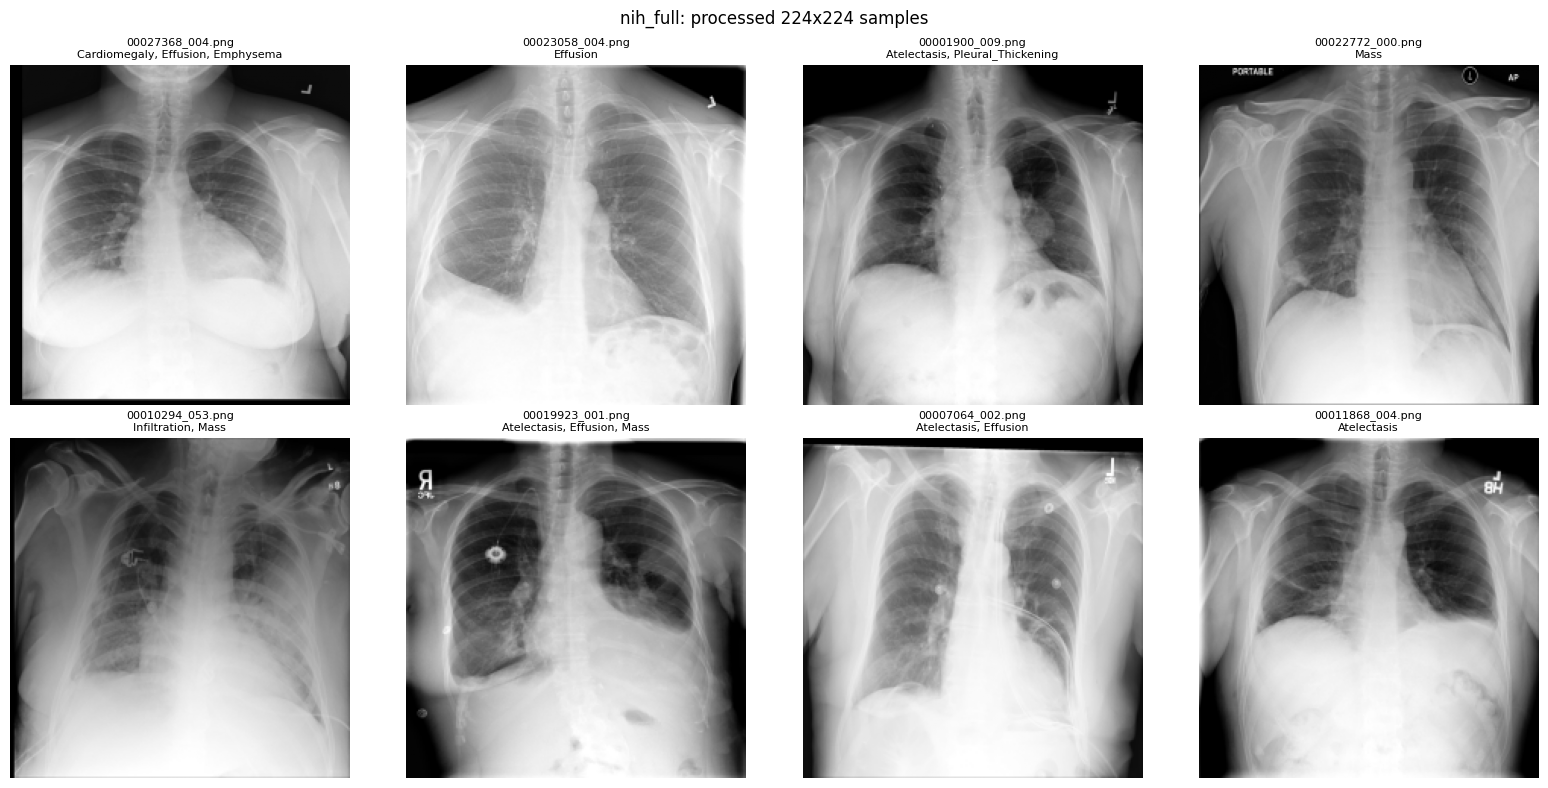

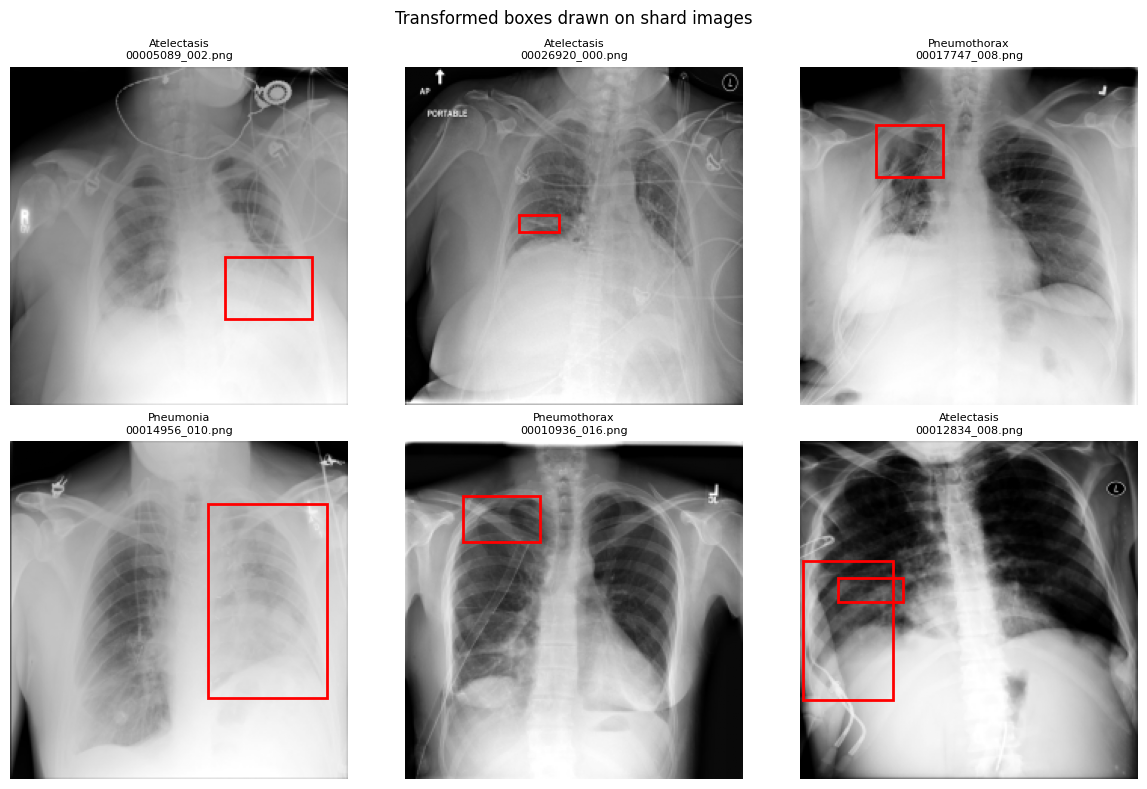

In [11]:
# [Cell 11] Random processed images from the shards, with transformed boxes where available
def read_processed(row):
    return np.load(row['shard_path'], mmap_mode='r')[row['shard_index']]

n_show = 8
picks = m.sample(min(n_show, len(m)), random_state=7)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for axis, (_, row) in zip(axes.flat, picks.iterrows()):
    axis.imshow(read_processed(row), cmap='gray', vmin=0, vmax=255)
    findings = [l for l in NIH_LABELS if row[l] == 1] or ['No Finding']
    axis.set_title(f'{row["Image Index"]}\n{", ".join(findings)}', fontsize=8)
    axis.axis('off')
for axis in axes.flat[len(picks):]:
    axis.axis('off')
plt.suptitle(f'{EXPORT_NAME}: processed {IMAGE_SIZE}x{IMAGE_SIZE} samples')
plt.tight_layout()
plt.show()

if len(nih_bbox_manifest):
    box_picks = (nih_bbox_manifest.drop_duplicates('Image Index')
                 .sample(min(6, nih_bbox_manifest['Image Index'].nunique()), random_state=7))
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for axis, (_, row) in zip(axes.flat, box_picks.iterrows()):
        axis.imshow(np.load(row['shard_path'], mmap_mode='r')[row['shard_index']], cmap='gray', vmin=0, vmax=255)
        for _, box in nih_bbox_manifest[nih_bbox_manifest['Image Index'] == row['Image Index']].iterrows():
            axis.add_patch(plt.Rectangle((box['box_x'], box['box_y']), box['box_w'], box['box_h'],
                                         fill=False, color='red', linewidth=2))
        axis.set_title(f'{row["Finding Label"]}\n{row["Image Index"]}', fontsize=8)
        axis.axis('off')
    for axis in axes.flat[len(box_picks):]:
        axis.axis('off')
    plt.suptitle('Transformed boxes drawn on shard images')
    plt.tight_layout()
    plt.show()

In [12]:
# [Cell 12] Label prevalence by split + metadata file
prevalence = m.groupby('official_split')[NIH_LABELS + ['no_finding']].sum().T
prevalence['total'] = prevalence.sum(axis=1)
display(prevalence)

meta = {
    'image_size': IMAGE_SIZE,
    'shard_size': SHARD_SIZE,
    'dtype': 'uint8',
    'preprocessing': 'grayscale, 1-99 percentile clip, aspect-preserving INTER_AREA resize, reflect-101 padding',
    'n_images': int(len(m)),
    'n_patients': int(m['patient_id'].nunique()),
    'n_shards': int(m['shard_path'].nunique()),
    'splits': {k: int(v) for k, v in m['official_split'].value_counts().items()},
    'target_labels': TARGET_LABELS,
    'native_labels': NIH_LABELS,
    'shared_label_columns': SHARED_LABELS,
    'n_boxes': int(len(nih_bbox_manifest)),
    'n_unreadable_dropped': int(len(nih_failed)),
    'n_missing_from_mount': int(len(missing)),
}
(EXPORT_ROOT / f'{EXPORT_NAME}_meta.json').write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))
print('\nFiles in', EXPORT_ROOT)
for p in sorted(EXPORT_ROOT.glob(f'{EXPORT_NAME}_*')):
    print(' ', p.name)

official_split,test,train_val,total
Atelectasis,3279,8280,11559
Cardiomegaly,1069,1707,2776
Effusion,4658,8659,13317
Infiltration,3426,5608,9034
Mass,1748,4034,5782
Nodule,1623,4708,6331
Pneumonia,258,390,648
Pneumothorax,2665,2637,5302
Consolidation,1815,2852,4667
Edema,433,584,1017


{
  "image_size": 224,
  "shard_size": 512,
  "dtype": "uint8",
  "preprocessing": "grayscale, 1-99 percentile clip, aspect-preserving INTER_AREA resize, reflect-101 padding",
  "n_images": 36823,
  "n_patients": 10296,
  "n_shards": 73,
  "splits": {
    "train_val": 25045,
    "test": 11778
  },
  "target_labels": [
    "Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Mass",
    "Nodule"
  ],
  "native_labels": [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural_Thickening",
    "Hernia"
  ],
  "shared_label_columns": [
    "Pleural Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Lung Lesion"
  ],
  "n_boxes": 896,
  "n_unreadable_dropped": 0,
  "n_missing_from_mount": 0
}

Files in /kaggle/working/outputs/processed
  nih_fu